In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Create the dataset (10 Students)
data = {
    'student_id': range(1, 11),
    'hours_studied': [2,3,4,5,6,7,8,9,10,11],
    'marks': [35, 40,43,48,52,57,61,66,70,74]
}

df = pd.DataFrame(data)

# Features (X) and Target (y)
X = df[['hours_studied']]
y = df['marks']

# 2. Initialize K-Fold (K=5)
# shuffle=True ensures data is randomized before splitting
kf = KFold(n_splits=5, shuffle=False)

model = LinearRegression()
mse_scores = []

print("--- Iteration Breakdown ---")

# 3. Run K-Fold Loop
for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    # Split data into train and test sets for the current fold
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Train the model
    model.fit(X_train, y_train)

    # Predict on the test set
    predictions = model.predict(X_test)

    # Calculate Mean Squared Error (MSE) for this fold
    mse = mean_squared_error(y_test, predictions)
    mse_scores.append(mse)

    print(f"Fold {fold}:")
    print(f"  Train Student IDs: {df['student_id'].iloc[train_idx].tolist()}")
    print(f"  Test Student IDs : {df['student_id'].iloc[test_idx].tolist()}")
    print(f"  Fold MSE        : {mse:.2f}\n")

# 4. Final Average Performance
print("--- Final Result ---")
print(f"Average Mean Squared Error across all 5 folds: {np.mean(mse_scores):.2f}")

--- Iteration Breakdown ---
Fold 1:
  Train Student IDs: [3, 4, 5, 6, 7, 8, 9, 10]
  Test Student IDs : [1, 2]
  Fold MSE        : 0.76

Fold 2:
  Train Student IDs: [1, 2, 5, 6, 7, 8, 9, 10]
  Test Student IDs : [3, 4]
  Fold MSE        : 0.40

Fold 3:
  Train Student IDs: [1, 2, 3, 4, 7, 8, 9, 10]
  Test Student IDs : [5, 6]
  Fold MSE        : 0.12

Fold 4:
  Train Student IDs: [1, 2, 3, 4, 5, 6, 9, 10]
  Test Student IDs : [7, 8]
  Fold MSE        : 0.17

Fold 5:
  Train Student IDs: [1, 2, 3, 4, 5, 6, 7, 8]
  Test Student IDs : [9, 10]
  Fold MSE        : 0.06

--- Final Result ---
Average Mean Squared Error across all 5 folds: 0.30



========== WITHOUT SHUFFLING ==========
Fold 1
Test rows: [1 2]
MSE = 0.762825963718839
Fold 2
Test rows: [3 4]
MSE = 0.4045138888888894
Fold 3
Test rows: [5 6]
MSE = 0.11810306365258785
Fold 4
Test rows: [7 8]
MSE = 0.17255015432099308
Fold 5
Test rows: [ 9 10]
MSE = 0.06023242630385692
MSE values: [0.762825963718839, 0.4045138888888894, 0.11810306365258785, 0.17255015432099308, 0.06023242630385692]
Average MSE = 0.30364509937703327

========== WITH SHUFFLING ==========
Fold 1
Test rows: [2 9]
MSE = 0.4004904875148655
Fold 2
Test rows: [1 6]
MSE = 0.03472222222222242
Fold 3
Test rows: [3 8]
MSE = 0.500637755102038
Fold 4
Test rows: [ 5 10]
MSE = 0.2118055555555516
Fold 5
Test rows: [4 7]
MSE = 0.017936390532544064
MSE values: [0.4004904875148655, 0.03472222222222242, 0.500637755102038, 0.2118055555555516, 0.017936390532544064]
Average MSE = 0.23311848218544431

========== COMPARISON ==========
Average MSE without shuffling: 0.30364509937703327
Average MSE with shuffling: 0.2331184821

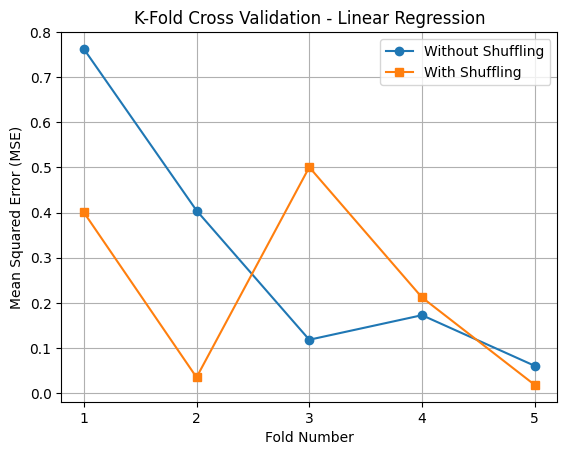

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


# -----------------------------
# 1. Read CSV file
# -----------------------------
#
data = {
    'student_id': range(1, 11),
    'hours_studied': [2,3,4,5,6,7,8,9,10,11],
    'marks': [35, 40,43,48,52,57,61,66,70,74]
}

df = pd.DataFrame(data)

X = df[["hours_studied"]]
y = df["marks"]

k = 5


# =========================================================
# METHOD 1: K-FOLD WITHOUT SHUFFLING
# =========================================================

print("\n========== WITHOUT SHUFFLING ==========")

kf_no_shuffle = KFold(
    n_splits=k,
    shuffle=False
)

mse_no_shuffle = []

fold = 1

for train_index, test_index in kf_no_shuffle.split(X):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    # Create model
    model = LinearRegression()

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Calculate MSE
    mse = mean_squared_error(y_test, y_pred)

    mse_no_shuffle.append(mse)

    print("Fold", fold)
    print("Test rows:", test_index + 1)
    print("MSE =", mse)

    fold += 1


average_no_shuffle = sum(mse_no_shuffle) / k

print("MSE values:", mse_no_shuffle)
print("Average MSE =", average_no_shuffle)


# =========================================================
# METHOD 2: K-FOLD WITH SHUFFLING
# =========================================================

print("\n========== WITH SHUFFLING ==========")

kf_shuffle = KFold(
    n_splits=k,
    shuffle=True,
    random_state=42
)

mse_shuffle = []

fold = 1

for train_index, test_index in kf_shuffle.split(X):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    # Create model
    model = LinearRegression()

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Calculate MSE
    mse = mean_squared_error(y_test, y_pred)

    mse_shuffle.append(mse)

    print("Fold", fold)
    print("Test rows:", test_index + 1)
    print("MSE =", mse)

    fold += 1


average_shuffle = sum(mse_shuffle) / k

print("MSE values:", mse_shuffle)
print("Average MSE =", average_shuffle)


# =========================================================
# COMPARISON
# =========================================================

print("\n========== COMPARISON ==========")

print("Average MSE without shuffling:",
      average_no_shuffle)

print("Average MSE with shuffling:",
      average_shuffle)


# =========================================================
# GRAPH
# =========================================================

plt.plot(
    range(1, k + 1),
    mse_no_shuffle,
    marker='o',
    label="Without Shuffling"
)

plt.plot(
    range(1, k + 1),
    mse_shuffle,
    marker='s',
    label="With Shuffling"
)

plt.xlabel("Fold Number")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("K-Fold Cross Validation - Linear Regression")

plt.xticks(range(1, k + 1))
plt.legend()
plt.grid(True)

plt.show()